# 01 - Exploratory Data Analysis (raw data)

This notebook explores the **raw** files exactly as provided. No cleaning, imputation or feature engineering is applied to the data;
any derived quantities (e.g. rate per mile, haversine distance) are computed only to *inspect* the data and are not saved.

Files:
- `data/train_test.csv` - labeled development data (`posted_rate` is the target)
- `data/validation.csv` - 12,000 loads requiring final predictions
- `data/december_chart_inputs.csv` - 31 fixed-lane rows for the December chart

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.4f}".format)

DATA_DIR = Path("..") / "data" if Path("..", "data").is_dir() else Path("data")
EQUIP_ORDER = ["Dry Van", "Reefer", "Flatbed"]
RNG = 42

In [2]:
train = pd.read_csv(DATA_DIR / "train_test.csv")
valid = pd.read_csv(DATA_DIR / "validation.csv")
dec = pd.read_csv(DATA_DIR / "december_chart_inputs.csv")
template = pd.read_csv(DATA_DIR / "validation_predictions_template.csv")

for name, df in {"train": train, "validation": valid, "december": dec, "template": template}.items():
    print(f"{name:<11} rows={len(df):>6,}  cols={df.shape[1]}")

train       rows=48,000  cols=14
validation  rows=12,000  cols=13
december    rows=    31  cols=7
template    rows=12,000  cols=2


## 1. Overview

In [3]:
train.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.0912,-76.7891,38.1691,-72.7456,274.3000,Dry Van,"30,658.0000",2025-01-01,0.9568,2.3960,645.4100
1,TR-000002,Richmond,Philadelphia,38.0912,-76.7891,39.2232,-72.9671,280.5000,Reefer,"17,555.0000",2025-01-01,0.9762,2.4335,679.9700
2,TR-000003,Philadelphia,Green Bay,39.2232,-72.9671,44.3030,-87.5287,967.8000,Dry Van,"31,721.0000",2025-01-01,1.0097,1.8449,"1,802.5400"
3,TR-000004,Hartford,Atlanta,39.5533,-72.1805,34.8493,-86.2894,965.4000,Dry Van,"32,333.0000",2025-01-01,0.9452,1.8771,"1,827.2800"
4,TR-000005,Dallas,Nashville,31.8302,-94.3834,35.2948,-88.0892,541.9000,Reefer,"35,183.0000",2025-01-01,0.9848,2.5630,"1,380.2800"


In [4]:
pd.DataFrame({
    "train_dtype": train.dtypes.astype(str),
    "valid_dtype": valid.dtypes.astype(str).reindex(train.columns),
    "train_unique": train.nunique(),
    "valid_unique": valid.nunique().reindex(train.columns),
})

,train_dtype,valid_dtype,train_unique,valid_unique
load_id,object,object,48000,"12,000.0000"
pickup,object,object,64,72.0000
delivery,object,object,64,72.0000
pickup_lat,float64,float64,64,72.0000
pickup_lon,float64,float64,63,71.0000
delivery_lat,float64,float64,64,72.0000
delivery_lon,float64,float64,63,71.0000
distance,float64,float64,21204,"9,309.0000"
equipment,object,object,3,3.0000
weight,float64,float64,23678,"9,472.0000"


## 2. Missing values

In [5]:
def missing_table(df):
    n = df.isna().sum()
    return pd.DataFrame({"missing": n, "pct": 100 * n / len(df)})

missing = pd.concat(
    {"train": missing_table(train), "validation": missing_table(valid)}, axis=1
)
missing

train        validation       
             missing    pct    missing    pct
load_id            0 0.0000     0.0000 0.0000
pickup             0 0.0000     0.0000 0.0000
delivery           0 0.0000     0.0000 0.0000
pickup_lat         0 0.0000     0.0000 0.0000
pickup_lon         0 0.0000     0.0000 0.0000
delivery_lat       0 0.0000     0.0000 0.0000
delivery_lon       0 0.0000     0.0000 0.0000
distance           0 0.0000     0.0000 0.0000
equipment          0 0.0000     0.0000 0.0000
weight           300 0.6250   165.0000 1.3750
date               0 0.0000     0.0000 0.0000
market_index     374 0.7792   249.0000 2.0750
quote_signal       0 0.0000     0.0000 0.0000
posted_rate        0 0.0000        NaN    NaN

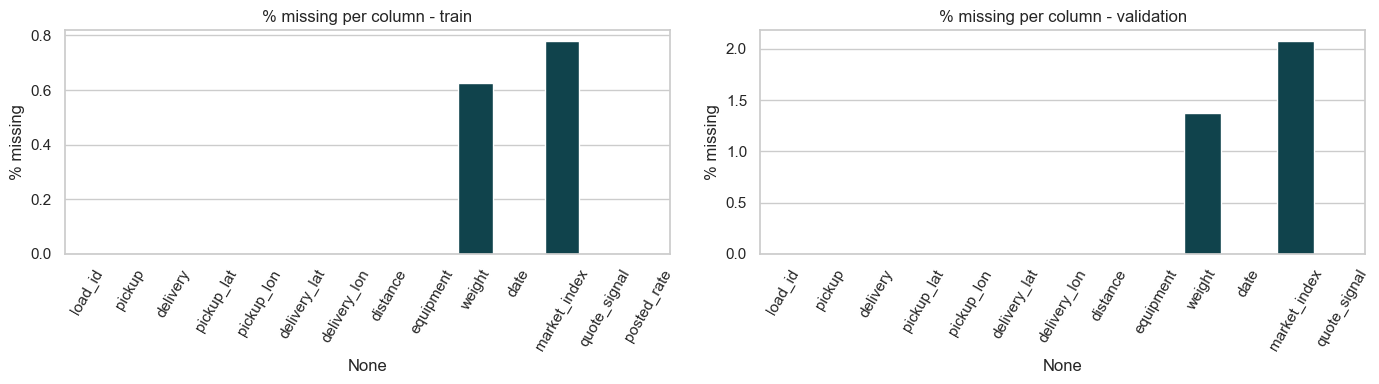

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (name, df) in zip(axes, {"train": train, "validation": valid}.items()):
    pct = 100 * df.isna().mean()
    sns.barplot(x=pct.index, y=pct.values, ax=ax, color="#064A56")
    ax.set_title(f"% missing per column - {name}")
    ax.set_ylabel("% missing")
    ax.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()

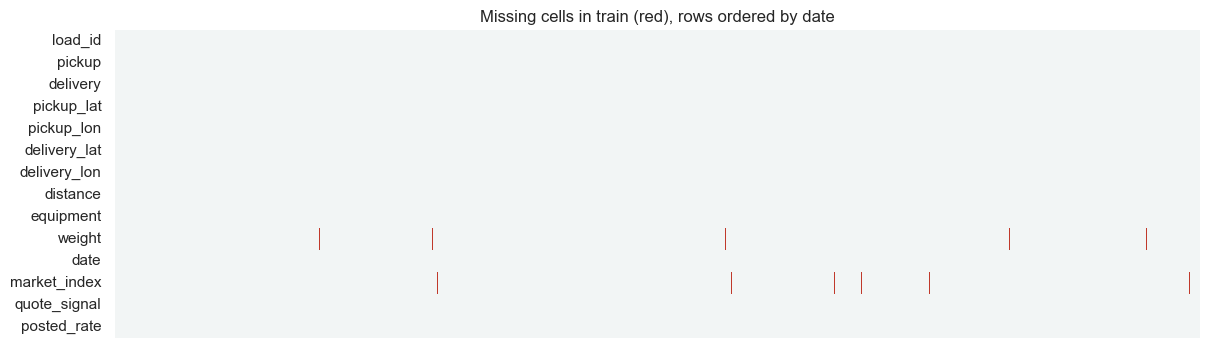

In [7]:
# Missingness map (rows sorted by date) - shows whether gaps cluster in time
fig, ax = plt.subplots(figsize=(14, 4))
sns.heatmap(train.sort_values("date").isna().T, cbar=False, cmap=["#F2F5F5", "#C0392B"], ax=ax, xticklabels=False)
ax.set_title("Missing cells in train (red), rows ordered by date")
plt.show()

In [8]:
# Does missingness depend on equipment or month?
tmp = train.assign(month=train["date"].str[:7])
pd.concat({
    "weight_missing_%": tmp.groupby("month")["weight"].apply(lambda s: 100 * s.isna().mean()),
    "market_index_missing_%": tmp.groupby("month")["market_index"].apply(lambda s: 100 * s.isna().mean()),
}, axis=1)

,weight_missing_%,market_index_missing_%
month,,
2025-01,0.6913,0.7320
2025-02,0.7609,0.8301
2025-03,0.7149,0.8737
2025-04,0.4150,0.6433
2025-05,0.4478,0.8752
2025-06,0.6690,0.8781
2025-07,0.5904,0.7329
2025-08,0.6094,0.6934
2025-09,0.7066,0.6638


In [9]:
print("Rows with BOTH weight and market_index missing:", (train["weight"].isna() & train["market_index"].isna()).sum())
train.groupby("equipment")[["weight", "market_index"]].apply(lambda d: 100 * d.isna().mean())

Rows with BOTH weight and market_index missing: 1


,weight,market_index
equipment,,
Dry Van,0.6433,0.7426
Flatbed,0.6284,0.8340
Reefer,0.5812,0.8219


## 3. Duplicates

In [10]:
feature_cols = [c for c in train.columns if c not in ("load_id", "posted_rate")]
print("Duplicate load_id (train):     ", train["load_id"].duplicated().sum())
print("Duplicate load_id (validation):", valid["load_id"].duplicated().sum())
print("Exact duplicate rows ignoring load_id (train):", train.drop(columns="load_id").duplicated().sum())
print("Same features, any rate (train):              ", train.duplicated(subset=feature_cols).sum())
print("Overlapping load_ids train/validation:        ", len(set(train["load_id"]) & set(valid["load_id"])))

Duplicate load_id (train):      0
Duplicate load_id (validation): 0
Exact duplicate rows ignoring load_id (train): 0
Same features, any rate (train):               0
Overlapping load_ids train/validation:         0


In [11]:
dupe_feats = train[train.duplicated(subset=feature_cols, keep=False)].sort_values(feature_cols)
dupe_feats.head(10)

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate


## 4. Numeric summary and impossible values

In [12]:
num_cols = ["pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon", "distance", "weight", "market_index", "quote_signal", "posted_rate"]
train[num_cols].describe(percentiles=[0.001, 0.01, 0.25, 0.5, 0.75, 0.99, 0.999]).T

,count,mean,std,min,0.1%,1%,25%,50%,75%,99%,99.9%,max
pickup_lat,"48,000.0000",35.6475,4.3153,28.3576,28.3576,28.3576,31.9869,35.2948,39.4110,44.3030,44.3030,44.3030
pickup_lon,"48,000.0000",-90.9290,13.4824,-121.6985,-121.6985,-119.7953,-98.4006,-88.0892,-83.2851,-69.5000,-69.5000,-69.5000
delivery_lat,"48,000.0000",35.6412,4.3172,28.3576,28.3576,28.3576,31.9869,35.2948,39.4110,44.3030,44.3030,44.3030
delivery_lon,"48,000.0000",-90.8573,13.4766,-121.6985,-121.6985,-119.7953,-98.4006,-87.5287,-83.2851,-69.5000,-69.5000,-69.5000
distance,"48,000.0000","1,135.8567",728.5644,70.0000,70.4995,121.8990,550.4000,953.3000,"1,645.5250","3,029.3040","3,256.7029","3,439.8000"
weight,"47,700.0000","31,028.8440","9,391.4406","-47,500.0000","-39,649.6720","9,801.9600","25,800.0000","31,436.5000","37,018.0000","47,500.0000","47,500.0000","47,500.0000"
market_index,"47,626.0000",1.0834,0.1681,0.6764,0.7418,0.7829,0.9497,1.0558,1.2196,1.4072,1.4404,1.4678
quote_signal,"48,000.0000",2.0625,0.2914,0.6923,0.9500,1.3047,1.8910,2.0558,2.2217,2.8840,3.2448,3.6103
posted_rate,"48,000.0000","2,373.9807","1,486.4932",57.2200,200.3099,327.1688,"1,251.5550","2,030.7600","3,330.7500","5,972.8340","12,854.5617","25,533.0000"


In [13]:
checks = {
    "weight <= 0": lambda d: d["weight"] <= 0,
    "weight > 48,000 lb": lambda d: d["weight"] > 48_000,
    "distance <= 0": lambda d: d["distance"] <= 0,
    "posted_rate <= 0": lambda d: d.get("posted_rate", pd.Series(np.nan, index=d.index)) <= 0,
    "market_index <= 0": lambda d: d["market_index"] <= 0,
    "quote_signal <= 0": lambda d: d["quote_signal"] <= 0,
    "pickup == delivery": lambda d: d["pickup"] == d["delivery"],
}
pd.DataFrame({
    "train": {k: int(f(train).sum()) for k, f in checks.items()},
    "validation": {k: int(f(valid).sum()) for k, f in checks.items()},
})

,train,validation
weight <= 0,292,145
"weight > 48,000 lb",0,0
distance <= 0,0,0
posted_rate <= 0,0,0
market_index <= 0,0,0
quote_signal <= 0,0,0
pickup == delivery,0,0


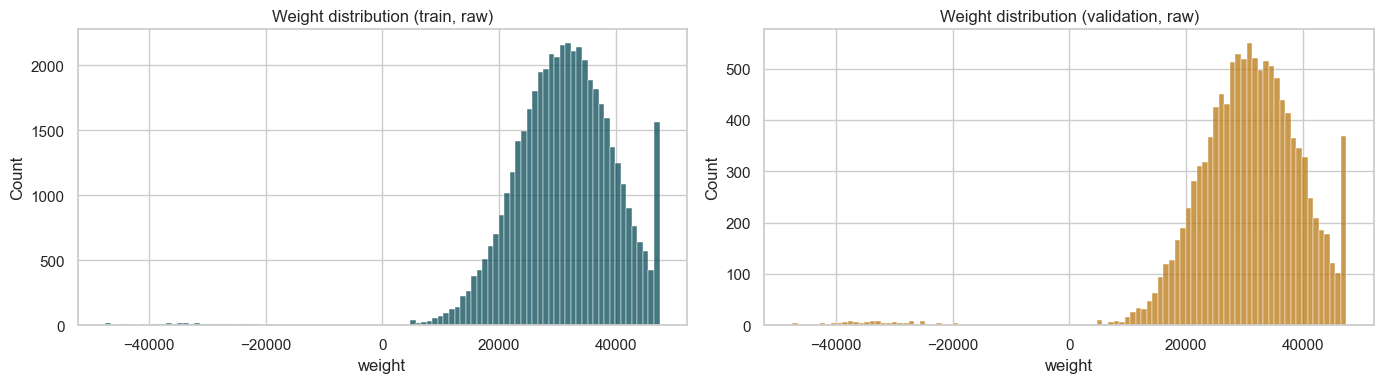

Negative weights - abs value range: 5000.0 to 47500.0


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
68,TR-000069,Amarillo,Dayton,33.1714,-104.3679,39.8721,-85.6293,"1,334.2000",Reefer,"-36,559.0000",2025-01-01,0.9610,2.1178,"2,831.2700"
204,TR-000205,Fresno,Tucson,33.0792,-119.7953,30.9273,-113.2304,496.2000,Dry Van,"-26,670.0000",2025-01-02,0.9690,2.1315,"1,046.9200"
206,TR-000207,Columbia,Raleigh,34.6357,-83.2851,35.3738,-77.4761,411.3000,Reefer,"-20,003.0000",2025-01-02,0.9480,2.3168,959.1500
225,TR-000226,Greensboro,Lubbock,35.9819,-82.7838,29.8753,-99.8546,"1,317.4000",Reefer,"-23,981.0000",2025-01-02,1.0082,2.1392,"2,836.0000"
376,TR-000377,Madison,Providence,41.7024,-89.8559,37.3729,-69.5000,"1,331.1000",Dry Van,"-41,397.0000",2025-01-03,0.9479,1.9187,"2,522.5400"


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(train["weight"], bins=100, ax=axes[0], color="#064A56")
axes[0].set_title("Weight distribution (train, raw)")
sns.histplot(valid["weight"], bins=100, ax=axes[1], color="#B9770E")
axes[1].set_title("Weight distribution (validation, raw)")
plt.tight_layout()
plt.show()

neg = train[train["weight"] < 0]
print("Negative weights - abs value range:", neg["weight"].abs().min(), "to", neg["weight"].abs().max())
neg.head()

## 5. Categorical columns

In [15]:
for col in ["equipment"]:
    print(pd.concat({"train": train[col].value_counts(dropna=False), "validation": valid[col].value_counts(dropna=False)}, axis=1), "\n")

print("Distinct pickup cities: ", train["pickup"].nunique())
print("Distinct delivery cities:", train["delivery"].nunique())

           train  validation
equipment                   
Dry Van    27202        6780
Reefer     12045        3051
Flatbed     8753        2169 

Distinct pickup cities:  64
Distinct delivery cities: 64


In [16]:
# Label variants: values that collide after lower-casing / stripping whitespace
def label_variants(series):
    s = series.dropna().astype(str)
    groups = s.groupby(s.str.strip().str.lower()).unique()
    return groups[groups.apply(len) > 1]

for col in ["pickup", "delivery", "equipment"]:
    v = pd.concat([label_variants(train[col]), label_variants(valid[col])])
    print(f"{col}: {len(v)} label groups with variants", list(v.items())[:10])

pickup: 0 label groups with variants []
delivery: 0 label groups with variants []
equipment: 0 label groups with variants []


In [17]:
cities_train = set(train["pickup"]) | set(train["delivery"])
cities_valid = set(valid["pickup"]) | set(valid["delivery"])
lanes_train = set(zip(train["pickup"], train["delivery"]))
lanes_valid = set(zip(valid["pickup"], valid["delivery"]))
valid_lane = list(zip(valid["pickup"], valid["delivery"]))

print("Cities in validation not in train:", sorted(cities_valid - cities_train))
print(f"Distinct lanes: train={len(lanes_train):,}  validation={len(lanes_valid):,}")
print(f"Validation lanes never seen in train: {len(lanes_valid - lanes_train):,}")
print(f"Validation rows on unseen lanes: {sum(l not in lanes_train for l in valid_lane):,} / {len(valid):,}")

Cities in validation not in train: ['Allentown', 'Charlotte', 'Chicago', 'Jackson', 'Knoxville', 'Laredo', 'Norfolk', 'San Diego']
Distinct lanes: train=4,014  validation=4,214
Validation lanes never seen in train: 736
Validation rows on unseen lanes: 1,461 / 12,000


## 6. Target: `posted_rate`

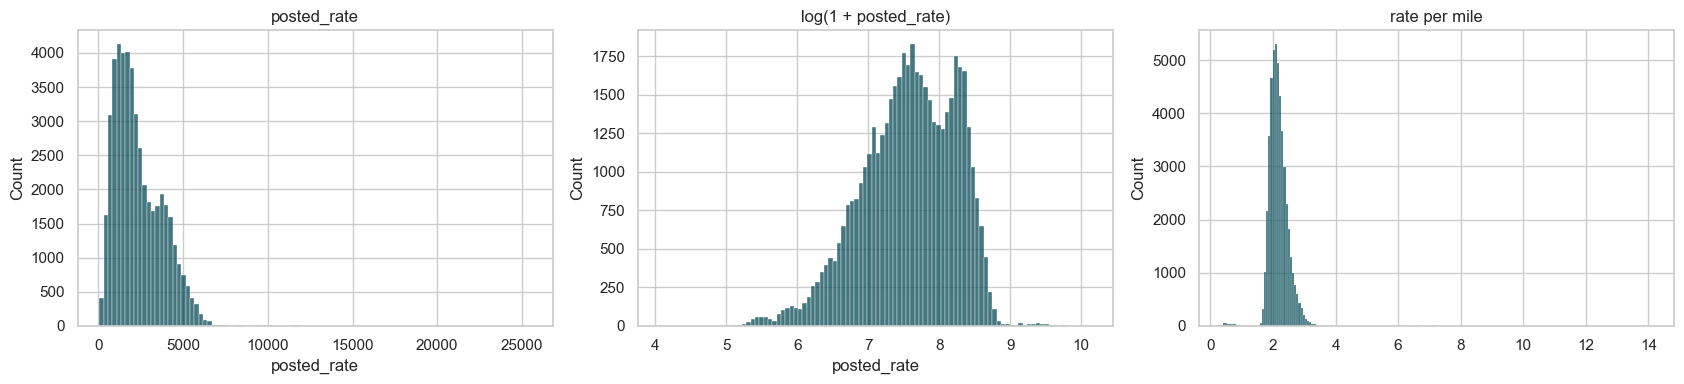

count   48,000.0000
mean         2.2153
std          0.5839
min          0.3337
0.1%         0.4374
1%           1.6735
5%           1.8075
50%          2.1453
95%          2.7359
99%          3.1769
99.9%       10.0688
max         14.1253
dtype: float64

In [18]:
rpm = train["posted_rate"] / train["distance"]   # inspection only, not stored

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(train["posted_rate"], bins=100, ax=axes[0], color="#064A56")
axes[0].set_title("posted_rate")
sns.histplot(np.log1p(train["posted_rate"]), bins=100, ax=axes[1], color="#064A56")
axes[1].set_title("log(1 + posted_rate)")
sns.histplot(rpm, bins=200, ax=axes[2], color="#064A56")
axes[2].set_title("rate per mile")
plt.tight_layout()
plt.show()

rpm.describe(percentiles=[0.001, 0.01, 0.05, 0.5, 0.95, 0.99, 0.999])

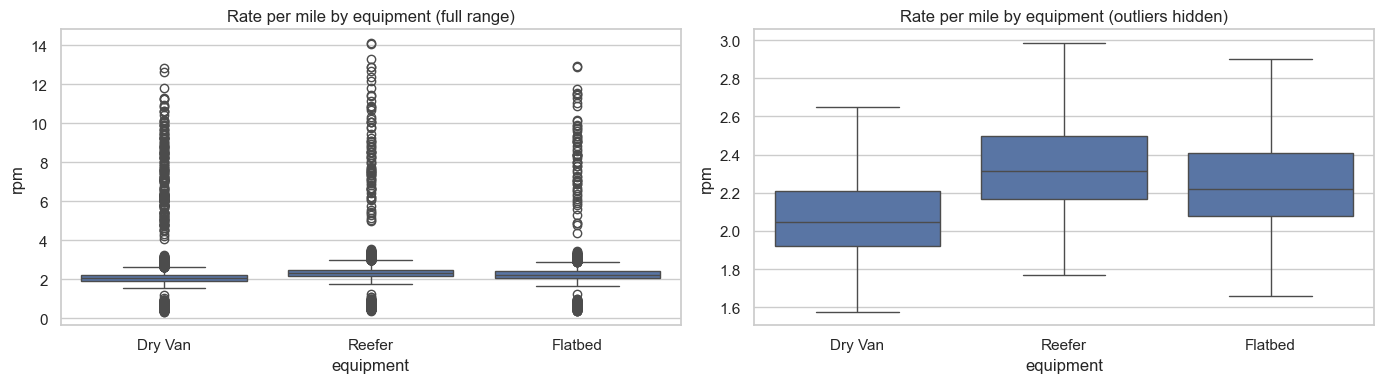

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=train.assign(rpm=rpm), x="equipment", y="rpm", order=EQUIP_ORDER, ax=axes[0])
axes[0].set_title("Rate per mile by equipment (full range)")
sns.boxplot(data=train.assign(rpm=rpm), x="equipment", y="rpm", order=EQUIP_ORDER, ax=axes[1], showfliers=False)
axes[1].set_title("Rate per mile by equipment (outliers hidden)")
plt.tight_layout()
plt.show()

In [20]:
# IQR-based outlier counts on rate per mile, per equipment
def iqr_outliers(s, k=3.0):
    q1, q3 = s.quantile([0.25, 0.75])
    return ((s < q1 - k * (q3 - q1)) | (s > q3 + k * (q3 - q1))).sum()

print("Rows outside 3*IQR of rate-per-mile within equipment:",
      train.assign(rpm=rpm).groupby("equipment")["rpm"].apply(iqr_outliers).to_dict())
train.assign(rpm=rpm).sort_values("rpm", ascending=False).head(10)

Rows outside 3*IQR of rate-per-mile within equipment: {'Dry Van': 376, 'Flatbed': 127, 'Reefer': 183}


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate,rpm
22254,TR-022255,Greensboro,Cincinnati,35.9819,-82.7838,37.1571,-86.7750,314.7000,Reefer,"-36,485.0000",2025-05-21,1.3726,1.2422,"4,445.2300",14.1253
36609,TR-036610,Chattanooga,Atlanta,35.2979,-87.1865,34.8493,-86.2894,98.4000,Reefer,"22,226.0000",2025-08-20,1.0347,2.5846,"1,386.4200",14.0896
870,TR-000871,Tulsa,Baton Rouge,33.4589,-94.7856,30.5013,-92.6537,305.6000,Reefer,"26,447.0000",2025-01-06,0.8086,2.6418,"4,069.2400",13.3156
17070,TR-017071,Toledo,Dayton,41.9766,-84.4590,39.8721,-85.6293,201.5000,Flatbed,"38,714.0000",2025-04-18,1.3028,1.4426,"2,609.3400",12.9496
27969,TR-027970,Buffalo,Boston,41.6768,-78.5670,39.2746,-69.5000,589.9000,Reefer,"24,951.0000",2025-06-25,1.3392,2.5880,"7,597.5200",12.8793
23369,TR-023370,Amarillo,Lubbock,33.1714,-104.3679,29.8753,-99.8546,412.4000,Flatbed,"35,494.0000",2025-05-28,1.3858,1.4058,"5,308.9600",12.8733
28012,TR-028013,Montgomery,Houston,31.3760,-86.1074,30.7116,-94.7655,604.3000,Reefer,"39,690.0000",2025-06-25,1.3114,2.7611,"7,773.3700",12.8634
45483,TR-045484,Greensboro,Columbia,35.9819,-82.7838,34.6357,-83.2851,153.8000,Dry Van,"34,198.0000",2025-10-15,1.0026,1.4639,"1,971.2100",12.8167
1415,TR-001416,Montgomery,Birmingham,31.3760,-86.1074,33.4579,-86.7279,198.2000,Reefer,"25,383.0000",2025-01-09,0.9966,2.6645,"2,509.9600",12.6638
21968,TR-021969,Jacksonville,Columbia,31.9869,-84.4890,34.6357,-83.2851,254.5000,Dry Van,"32,993.0000",2025-05-19,1.2128,1.5287,"3,220.6600",12.6549


In [21]:
train.assign(rpm=rpm).sort_values('rpm').head(10)

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate,rpm
14102,TR-014103,Buffalo,Bakersfield,41.6768,-78.5670,33.2883,-116.6793,"2,536.4000",Dry Van,"27,044.0000",2025-03-30,1.0339,1.7726,846.4200,0.3337
25798,TR-025799,Albany,Reno,43.9697,-71.0584,39.5484,-118.6484,"2,894.3000",Dry Van,"32,383.0000",2025-06-12,1.3384,1.8800,969.8300,0.3351
23043,TR-023044,Phoenix,Philadelphia,28.7567,-115.8773,39.2232,-72.9671,"2,983.4000",Dry Van,"37,692.0000",2025-05-26,1.1683,2.3169,"1,047.9100",0.3512
46173,TR-046174,Philadelphia,El Paso,39.2232,-72.9671,33.3107,-110.3123,"2,490.9000",Dry Van,"22,411.0000",2025-10-20,0.8788,2.4055,880.1300,0.3533
508,TR-000509,Las Vegas,Grand Rapids,33.2235,-115.2499,43.4380,-86.2917,"1,976.4000",Flatbed,"28,233.0000",2025-01-04,0.8631,1.8220,699.4100,0.3539
2511,TR-002512,Buffalo,San Antonio,41.6768,-78.5670,29.5097,-98.4006,"1,644.3000",Flatbed,"22,022.0000",2025-01-16,0.9994,1.8731,596.0400,0.3625
40600,TR-040601,Fort Wayne,Phoenix,41.3156,-85.3621,28.7567,-115.8773,"2,210.6000",Dry Van,"24,954.0000",2025-09-14,0.7828,1.7273,808.7400,0.3658
22458,TR-022459,Salt Lake City,Mobile,35.0349,-113.1890,31.8044,-88.2519,"1,632.3000",Dry Van,"-32,048.0000",2025-05-22,1.4319,2.1075,599.7700,0.3674
22464,TR-022465,Kansas City,Los Angeles,39.4110,-91.1245,28.5662,-116.7025,"1,909.1000",Dry Van,"32,899.0000",2025-05-22,1.4101,2.0978,709.4600,0.3716
1555,TR-001556,El Paso,New York,33.3107,-110.3123,40.0067,-73.7984,"2,415.0000",Dry Van,"39,284.0000",2025-01-10,0.9709,1.8324,911.4400,0.3774


## 7. Correlation matrix

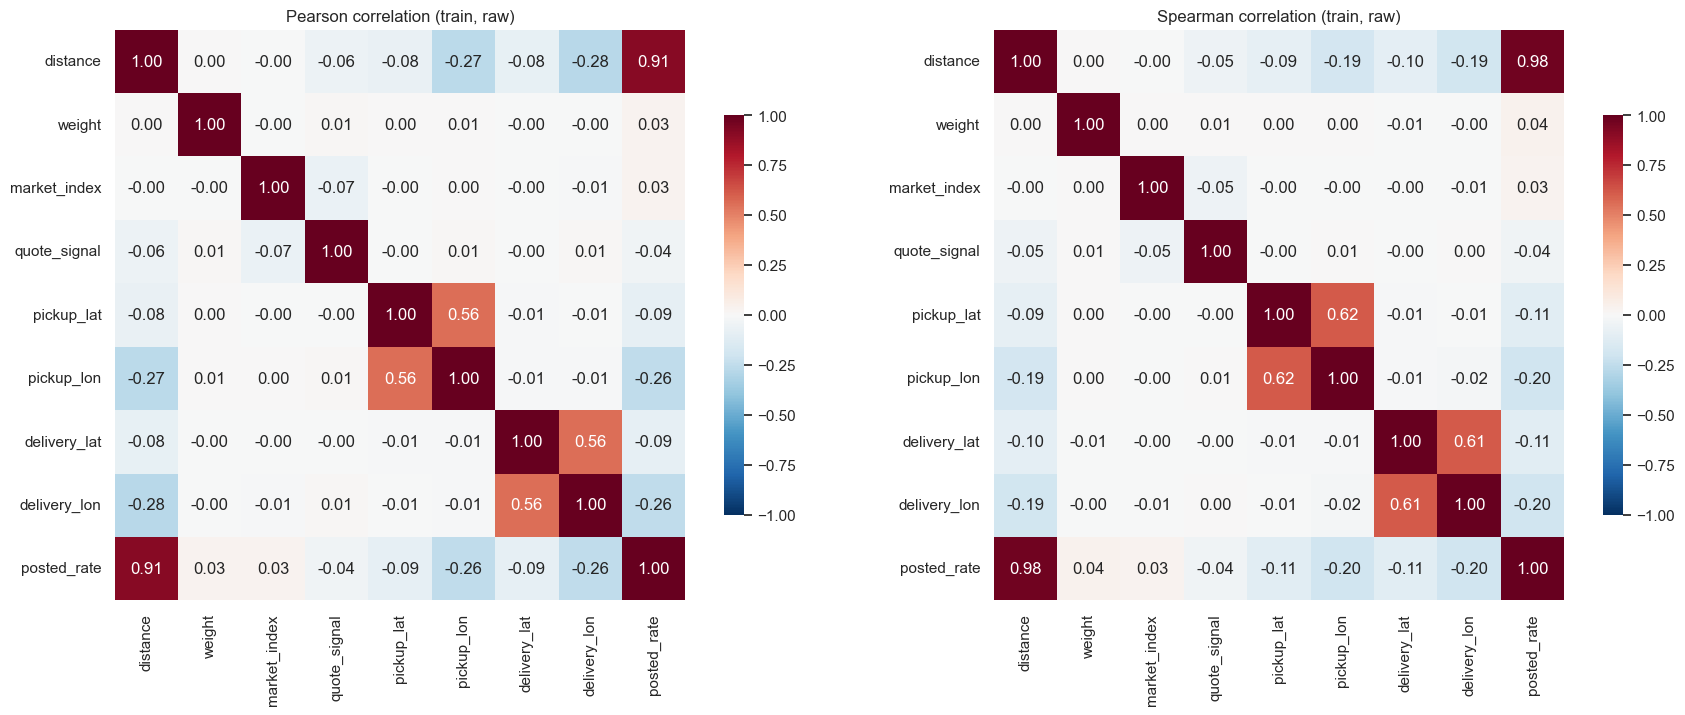

In [22]:
corr_cols = ["distance", "weight", "market_index", "quote_signal", "pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon", "posted_rate"]
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, method in zip(axes, ["pearson", "spearman"]):
    c = train[corr_cols].corr(method=method)
    sns.heatmap(c, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=ax, cbar_kws={"shrink": 0.7})
    ax.set_title(f"{method.title()} correlation (train, raw)")
plt.tight_layout()
plt.show()

In [23]:
# Correlation with rate per mile, which removes the dominant distance effect
train[corr_cols].assign(rate_per_mile=rpm).corr(method="spearman")["rate_per_mile"].drop("rate_per_mile").sort_values()

distance       -0.7357
posted_rate    -0.6197
pickup_lat     -0.0445
delivery_lat   -0.0418
delivery_lon    0.0499
pickup_lon      0.0501
quote_signal    0.0911
market_index    0.1798
weight          0.1961
Name: rate_per_mile, dtype: float64

## 8. Relationships with the target

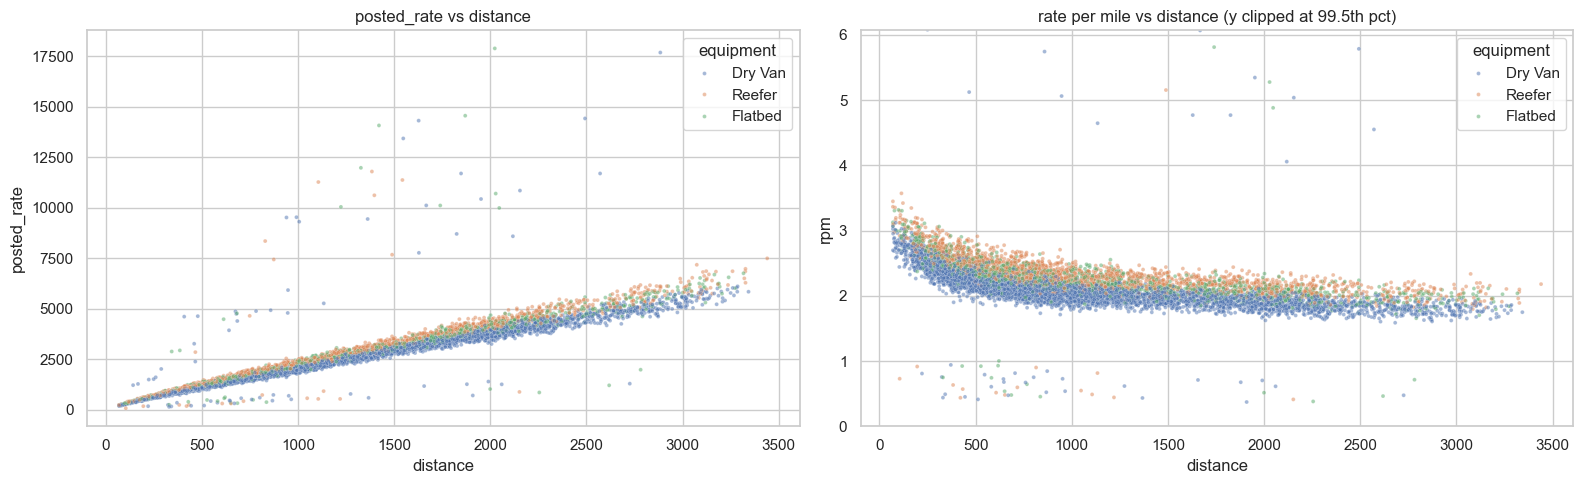

In [24]:
sample = train.assign(rpm=rpm).sample(8_000, random_state=RNG)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.scatterplot(data=sample, x="distance", y="posted_rate", hue="equipment", hue_order=EQUIP_ORDER, s=8, alpha=0.5, ax=axes[0])
axes[0].set_title("posted_rate vs distance")
sns.scatterplot(data=sample, x="distance", y="rpm", hue="equipment", hue_order=EQUIP_ORDER, s=8, alpha=0.5, ax=axes[1])
axes[1].set_ylim(0, sample["rpm"].quantile(0.995))
axes[1].set_title("rate per mile vs distance (y clipped at 99.5th pct)")
plt.tight_layout()
plt.show()

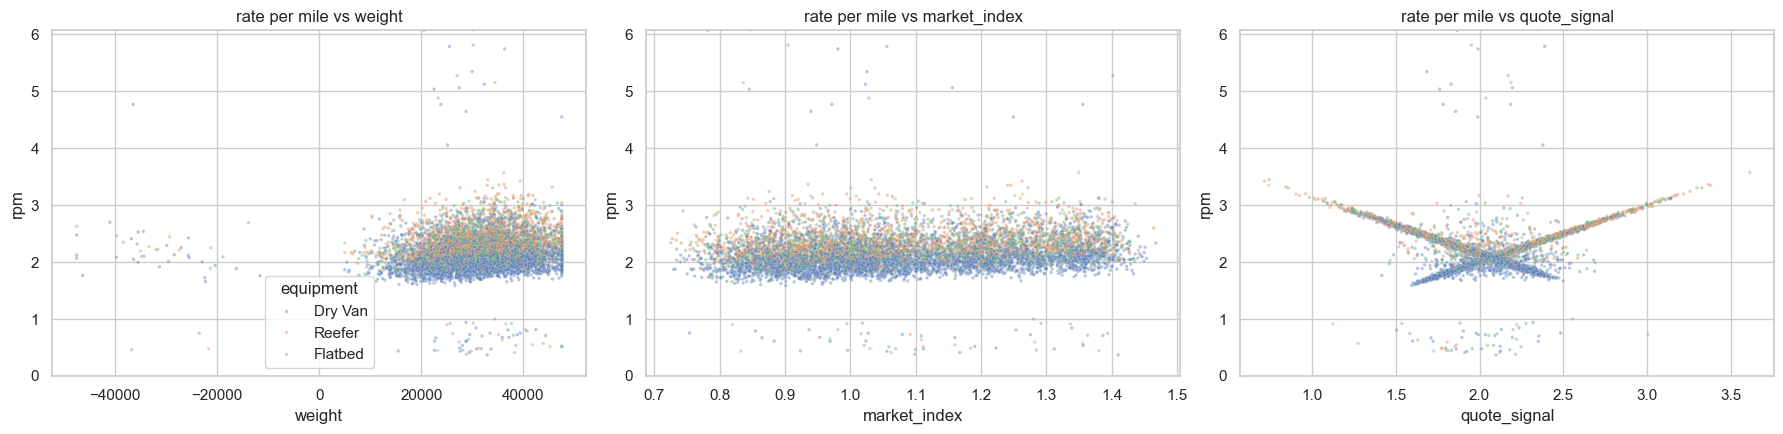

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, col in zip(axes, ["weight", "market_index", "quote_signal"]):
    sns.scatterplot(data=sample, x=col, y="rpm", hue="equipment", hue_order=EQUIP_ORDER, s=6, alpha=0.4, ax=ax, legend=ax is axes[0])
    ax.set_ylim(0, sample["rpm"].quantile(0.995))
    ax.set_title(f"rate per mile vs {col}")
plt.tight_layout()
plt.show()

In [26]:
bins = [0, 250, 500, 750, 1000, 1500, 2000, 2500, 3500]
(train.assign(rpm=rpm, distance_band=pd.cut(train["distance"], bins))
      .pivot_table(index="distance_band", columns="equipment", values="rpm", aggfunc="median", observed=True)[EQUIP_ORDER])

equipment,Dry Van,Reefer,Flatbed
distance_band,,,
"(0, 250]",2.6346,2.9620,2.8496
"(250, 500]",2.3247,2.6309,2.5206
"(500, 750]",2.1506,2.4309,2.3321
"(750, 1000]",2.0671,2.3343,2.2283
"(1000, 1500]",1.9971,2.2547,2.1622
"(1500, 2000]",1.9233,2.1736,2.0855
"(2000, 2500]",1.8625,2.0989,2.0140
"(2500, 3500]",1.8004,2.0325,1.9556


## 9. Time patterns

In [27]:
t = train.assign(date=pd.to_datetime(train["date"]), rpm=rpm)
v = valid.assign(date=pd.to_datetime(valid["date"]))
print("Train dates:     ", t["date"].min().date(), "to", t["date"].max().date(), f"({t['date'].nunique()} days)")
print("Validation dates:", v["date"].min().date(), "to", v["date"].max().date(), f"({v['date'].nunique()} days)")
missing_days = pd.date_range(t["date"].min(), t["date"].max()).difference(t["date"].unique())
print("Calendar days with no train loads:", len(missing_days), list(missing_days.date[:10]))

Train dates:      2025-01-01 to 2025-10-31 (304 days)
Validation dates: 2025-11-01 to 2025-12-31 (61 days)
Calendar days with no train loads: 0 []


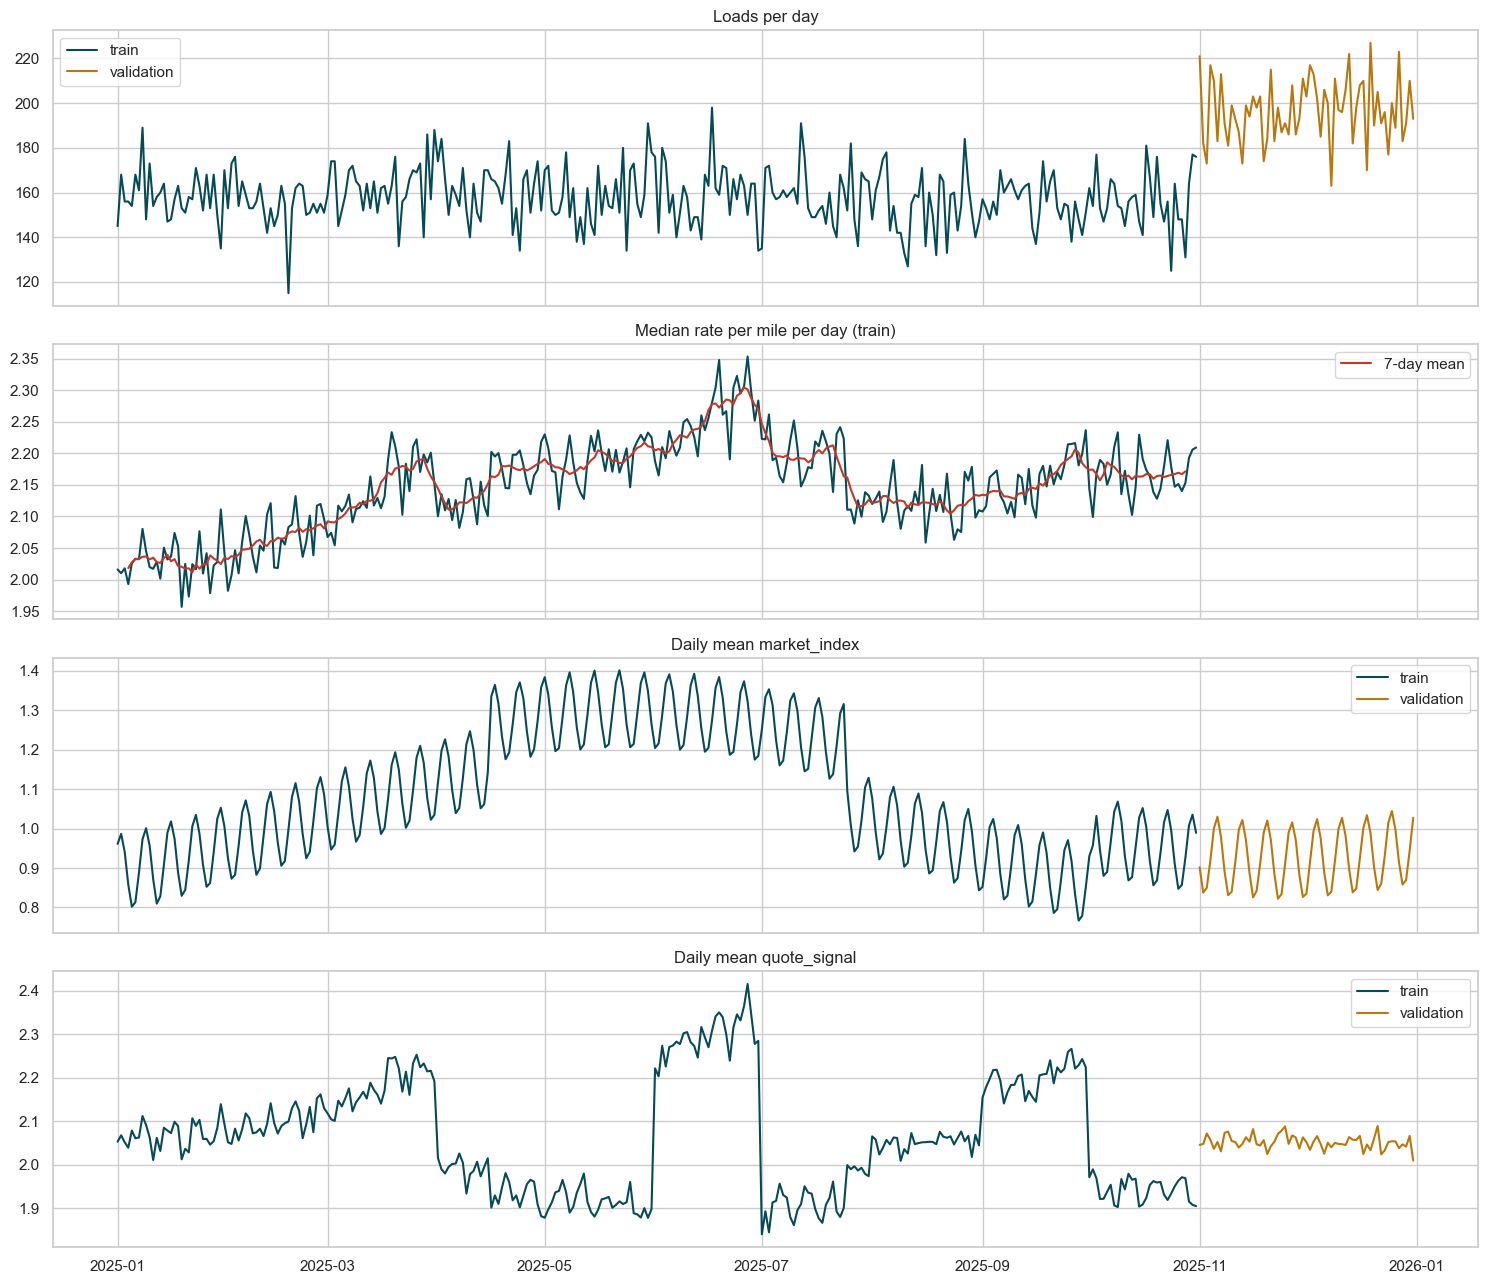

In [28]:
daily = t.groupby("date").agg(loads=("load_id", "size"), median_rpm=("rpm", "median"),
                              market_index=("market_index", "mean"), quote_signal=("quote_signal", "mean"))
vdaily = v.groupby("date").agg(loads=("load_id", "size"), market_index=("market_index", "mean"), quote_signal=("quote_signal", "mean"))

fig, axes = plt.subplots(4, 1, figsize=(15, 13), sharex=True)
axes[0].plot(daily.index, daily["loads"], color="#064A56", label="train")
axes[0].plot(vdaily.index, vdaily["loads"], color="#B9770E", label="validation")
axes[0].set_title("Loads per day"); axes[0].legend()
axes[1].plot(daily.index, daily["median_rpm"], color="#064A56")
axes[1].plot(daily.index, daily["median_rpm"].rolling(7, center=True).mean(), color="#C0392B", label="7-day mean")
axes[1].set_title("Median rate per mile per day (train)"); axes[1].legend()
for ax, col in zip(axes[2:], ["market_index", "quote_signal"]):
    ax.plot(daily.index, daily[col], color="#064A56", label="train")
    ax.plot(vdaily.index, vdaily[col], color="#B9770E", label="validation")
    ax.set_title(f"Daily mean {col}"); ax.legend()
plt.tight_layout()
plt.show()

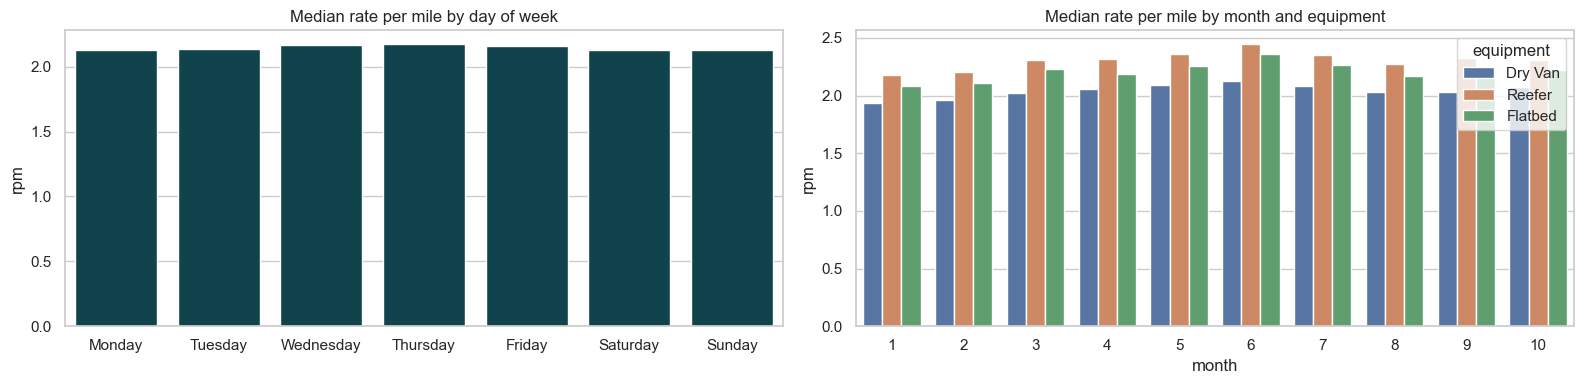

In [29]:
dow_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
sns.barplot(data=t, x=t["date"].dt.day_name(), y="rpm", order=dow_order, estimator=np.median, errorbar=None, ax=axes[0], color="#064A56")
axes[0].set_title("Median rate per mile by day of week"); axes[0].set_xlabel("")
sns.barplot(data=t, x=t["date"].dt.month, y="rpm", hue="equipment", hue_order=EQUIP_ORDER, estimator=np.median, errorbar=None, ax=axes[1])
axes[1].set_title("Median rate per mile by month and equipment"); axes[1].set_xlabel("month")
plt.tight_layout()
plt.show()

In [30]:
# How closely does each market signal track the daily price level?
daily[["median_rpm", "market_index", "quote_signal"]].corr(method="spearman")

,median_rpm,market_index,quote_signal
median_rpm,1.0000,0.6378,-0.0858
market_index,0.6378,1.0000,-0.2397
quote_signal,-0.0858,-0.2397,1.0000


In [31]:
# Is market_index effectively a daily value? Compare spread within a day to spread across days
by_day = train.groupby("date")["market_index"]
print(f"Median within-day std:  {by_day.std().median():.4f}")
print(f"Std of daily medians:   {by_day.median().std():.4f}")
print(f"Days with a missing market_index that still have other values that day: "
      f"{train.loc[train['market_index'].isna(), 'date'].isin(train.dropna(subset=['market_index'])['date']).mean():.0%}")

Median within-day std:  0.0248
Std of daily medians:   0.1665
Days with a missing market_index that still have other values that day: 100%


## 10. Consistency checks

In [32]:
# Each city should map to exactly one coordinate pair
coords = pd.concat([
    train[["pickup", "pickup_lat", "pickup_lon"]].set_axis(["city", "lat", "lon"], axis=1),
    train[["delivery", "delivery_lat", "delivery_lon"]].set_axis(["city", "lat", "lon"], axis=1),
    valid[["pickup", "pickup_lat", "pickup_lon"]].set_axis(["city", "lat", "lon"], axis=1),
    valid[["delivery", "delivery_lat", "delivery_lon"]].set_axis(["city", "lat", "lon"], axis=1),
])
coord_counts = coords.drop_duplicates().groupby("city").size()
print("Cities with more than one coordinate pair:", (coord_counts > 1).sum())
coords.drop_duplicates().sort_values("city").head(10)

Cities with more than one coordinate pair: 0


,city,lat,lon
16,Albany,43.9697,-71.0584
9,Albuquerque,35.3992,-109.5979
49,Allentown,40.0168,-73.8089
36,Amarillo,33.1714,-104.3679
25,Atlanta,34.8493,-86.2894
19,Austin,29.3955,-99.6978
8,Bakersfield,33.2883,-116.6793
85,Baltimore,38.1691,-72.7456
40,Baton Rouge,30.5013,-92.6537
67,Birmingham,33.4579,-86.7279


count   48,000.0000
mean         1.1947
std          0.1435
min          1.0581
0.1%         1.1122
1%           1.1296
50%          1.1822
99%          1.4039
99.9%        1.7365
max          9.6349
dtype: float64


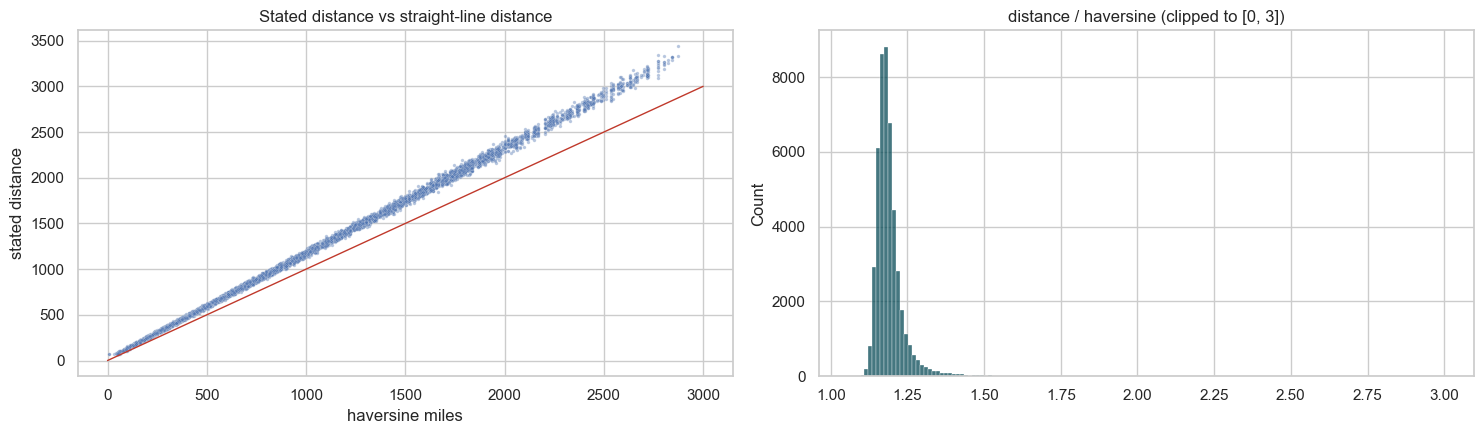

In [33]:
def haversine_miles(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 3958.8 * 2 * np.arcsin(np.sqrt(a))

hav = haversine_miles(train["pickup_lat"], train["pickup_lon"], train["delivery_lat"], train["delivery_lon"])
ratio = train["distance"] / hav
print(ratio.describe(percentiles=[0.001, 0.01, 0.5, 0.99, 0.999]))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.scatterplot(x=hav.sample(8_000, random_state=RNG), y=train["distance"].sample(8_000, random_state=RNG), s=6, alpha=0.4, ax=axes[0])
axes[0].plot([0, 3000], [0, 3000], color="#C0392B", lw=1)
axes[0].set_xlabel("haversine miles"); axes[0].set_ylabel("stated distance"); axes[0].set_title("Stated distance vs straight-line distance")
sns.histplot(ratio.clip(0, 3), bins=150, ax=axes[1], color="#064A56")
axes[1].set_title("distance / haversine (clipped to [0, 3])")
plt.tight_layout()
plt.show()

In [34]:
# For rows flagged as > 1.5x straight-line distance: is the stated distance wrong, or is the trip just short?
flag = ratio > 1.5
lane_median = train[~flag].groupby(["pickup", "delivery"])["distance"].median().rename("lane_median_distance")
flagged = train[flag].join(lane_median, on=["pickup", "delivery"])

print(f"Flagged rows: {flag.sum()} train")
print(f"Median stated distance, flagged vs normal: {train.loc[flag, 'distance'].median():.0f} vs {train.loc[~flag, 'distance'].median():.0f} mi")
print(f"Flagged rows with same-lane history: {flagged['lane_median_distance'].notna().sum()}, "
      f"median stated / lane-median distance: {(flagged['distance'] / flagged['lane_median_distance']).median():.2f}")
print(f"Median rate per mile, normal rows:                   {(train.loc[~flag, 'posted_rate'] / train.loc[~flag, 'distance']).median():.2f}")
print(f"Median rate per mile, flagged rows, stated distance: {(train.loc[flag, 'posted_rate'] / train.loc[flag, 'distance']).median():.2f}")
print(f"Median rate per mile, flagged rows, 1.18 x haversine: {(train.loc[flag, 'posted_rate'] / (1.18 * hav[flag])).median():.2f}")

Flagged rows: 214 train
Median stated distance, flagged vs normal: 89 vs 957 mi
Flagged rows with same-lane history: 175, median stated / lane-median distance: 1.14
Median rate per mile, normal rows:                   2.14
Median rate per mile, flagged rows, stated distance: 2.91
Median rate per mile, flagged rows, 1.18 x haversine: 4.04


In [35]:
# Same lane should have (nearly) the same distance
lane_dist = train.groupby(["pickup", "delivery"])["distance"].agg(["count", "min", "max", "std"])
lane_dist["spread"] = lane_dist["max"] - lane_dist["min"]
print(lane_dist["spread"].describe())
lane_dist.sort_values("spread", ascending=False).head(10)

count   4,014.0000
mean       59.6489
std        39.3240
min         0.0000
25%        32.3250
50%        48.9000
75%        78.2750
max       273.5000
Name: spread, dtype: float64


,,count,min,max,std,spread
pickup,delivery,,,,,
Los Angeles,Boston,12,"3,069.1000","3,342.6000",67.2445,273.5000
Hartford,Tucson,23,"2,637.5000","2,866.1000",58.2802,228.6000
Harrisburg,San Francisco,9,"2,652.5000","2,875.3000",68.2009,222.8000
Cincinnati,Los Angeles,20,"2,028.6000","2,249.0000",46.8629,220.4000
Phoenix,Syracuse,28,"2,633.9000","2,851.1000",50.0086,217.2000
New York,El Paso,20,"2,301.9000","2,515.3000",51.4244,213.4000
Bakersfield,Boston,11,"2,920.9000","3,133.3000",63.5043,212.4000
San Francisco,Providence,5,"3,228.2000","3,439.8000",88.5335,211.6000
Phoenix,Washington,11,"2,599.9000","2,810.7000",57.5647,210.8000


## 11. Lanes and the December lane

In [36]:
lane_stats = (train.assign(rpm=rpm).groupby(["pickup", "delivery"])
              .agg(loads=("load_id", "size"), median_rate=("posted_rate", "median"), median_rpm=("rpm", "median"))
              .sort_values("loads", ascending=False))
print("Loads per lane:"); print(lane_stats["loads"].describe())
lane_stats.head(15)

Loads per lane:
count   4,014.0000
mean       11.9581
std         7.1650
min         1.0000
25%         6.0000
50%        10.0000
75%        16.0000
max        39.0000
Name: loads, dtype: float64


,,loads,median_rate,median_rpm
pickup,delivery,,,
Lexington,Atlanta,39,553.6300,2.6909
Phoenix,Shreveport,39,"3,554.4300",2.1259
Columbia,Oklahoma City,39,"2,327.4300",2.1976
Fort Wayne,Philadelphia,38,"1,708.8350",2.1581
Richmond,Oklahoma City,37,"3,126.4900",2.0136
Lexington,Kansas City,37,"1,029.8000",2.3080
Shreveport,Hartford,37,"2,812.5200",1.9764
Fort Wayne,Hartford,37,"1,725.9900",2.0873
Lexington,Cincinnati,37,377.1000,2.8210


In [37]:
lex_fw = t[(t["pickup"] == "Lexington") & (t["delivery"] == "Fort Wayne")]
print(f"Lexington -> Fort Wayne loads in train: {len(lex_fw)}  (Dry Van: {(lex_fw['equipment'] == 'Dry Van').sum()})")
lex_fw.sort_values("date")[["date", "equipment", "distance", "weight", "market_index", "quote_signal", "posted_rate", "rpm"]].tail(20)

Lexington -> Fort Wayne loads in train: 32  (Dry Van: 21)


,date,equipment,distance,weight,market_index,quote_signal,posted_rate,rpm
15930,2025-04-11,Dry Van,360.5000,"40,999.0000",1.1745,1.7615,849.1700,2.3555
16131,2025-04-12,Reefer,366.6000,"29,496.0000",1.0905,1.6268,918.7100,2.5060
16192,2025-04-12,Flatbed,358.0000,"22,382.0000",1.0822,1.7945,844.1300,2.3579
18208,2025-04-25,Flatbed,357.8000,"41,138.0000",1.3492,1.5554,919.7600,2.5706
18777,2025-04-28,Dry Van,366.6000,"23,287.0000",1.2260,1.8312,848.0500,2.3133
22418,2025-05-22,Dry Van,372.9000,"35,578.0000",1.4062,1.7820,896.6300,2.4045
23524,2025-05-29,Dry Van,378.8000,"39,179.0000",1.3837,1.6993,934.3700,2.4667
26302,2025-06-15,Dry Van,359.7000,"19,949.0000",1.2352,2.3008,824.3900,2.2919
31113,2025-07-15,Dry Van,362.5000,"36,951.0000",1.2656,1.7259,880.6300,2.4293
32730,2025-07-25,Flatbed,354.7000,"24,941.0000",1.0818,1.6728,877.8400,2.4749


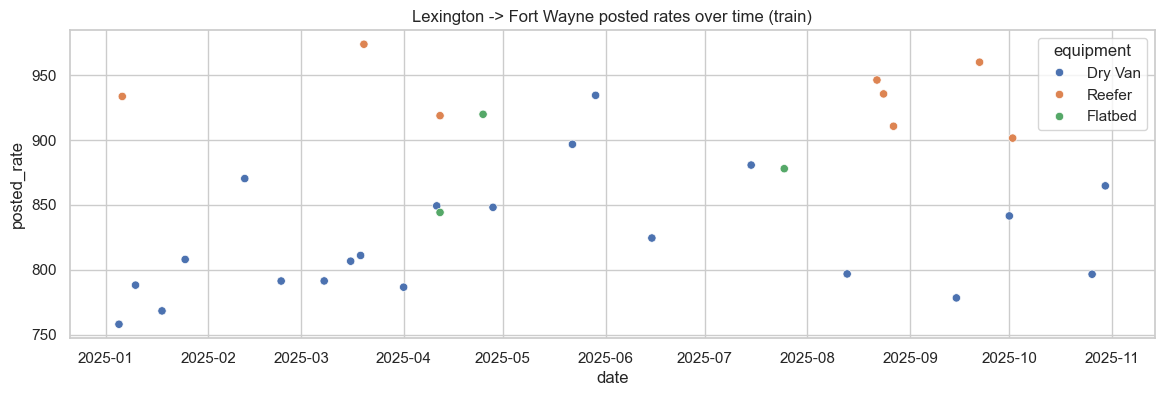

In [38]:
fig, ax = plt.subplots(figsize=(14, 4))
sns.scatterplot(data=lex_fw, x="date", y="posted_rate", hue="equipment", hue_order=EQUIP_ORDER, ax=ax)
ax.set_title("Lexington -> Fort Wayne posted rates over time (train)")
plt.show()

In [39]:
# December inputs: note which model inputs are NOT provided
print("December columns:", list(dec.columns))
print("Train columns missing from December inputs:", [c for c in train.columns if c not in dec.columns and c not in ("load_id", "posted_rate")])
dec.head()

December columns: ['pickup', 'delivery', 'distance', 'equipment', 'weight', 'date', 'predicted_rate']
Train columns missing from December inputs: ['pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'market_index', 'quote_signal']


,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,NaN
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,NaN
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,NaN
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,NaN
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,NaN


December dates covered by validation.csv: 31 / 31
Lexington and Fort Wayne in the city lookup: {'Lexington': True, 'Fort Wayne': True}


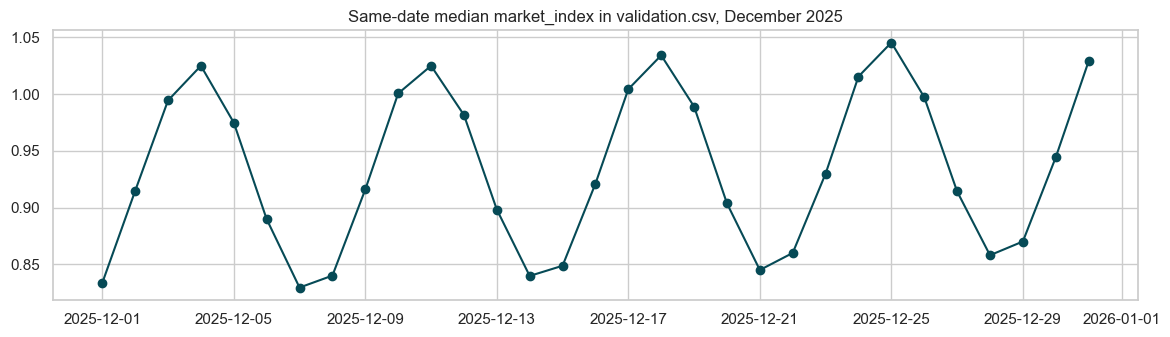

,market_index,quote_signal
count,31.0000,31.0000
mean,0.9346,2.0470
std,0.0715,0.0199
min,0.8295,1.9954
25%,0.8650,2.0354
50%,0.9211,2.0461
75%,0.9990,2.0598
max,1.0455,2.0866


In [40]:
# The missing December inputs are available from validation.csv (features only, no target)
dec_dates = pd.to_datetime(dec["date"])
v_daily = v.groupby("date")[["market_index", "quote_signal"]].median()
print("December dates covered by validation.csv:", dec_dates.isin(v_daily.index).sum(), "/", len(dec))
print("Lexington and Fort Wayne in the city lookup:",
      {c: c in set(coords["city"]) for c in ["Lexington", "Fort Wayne"]})

fig, ax = plt.subplots(figsize=(14, 3.5))
ax.plot(v_daily.loc["2025-12"].index, v_daily.loc["2025-12", "market_index"], marker="o", color="#064A56")
ax.set_title("Same-date median market_index in validation.csv, December 2025")
plt.show()
v_daily.loc["2025-12"].describe()

## 12. Train vs validation distributions

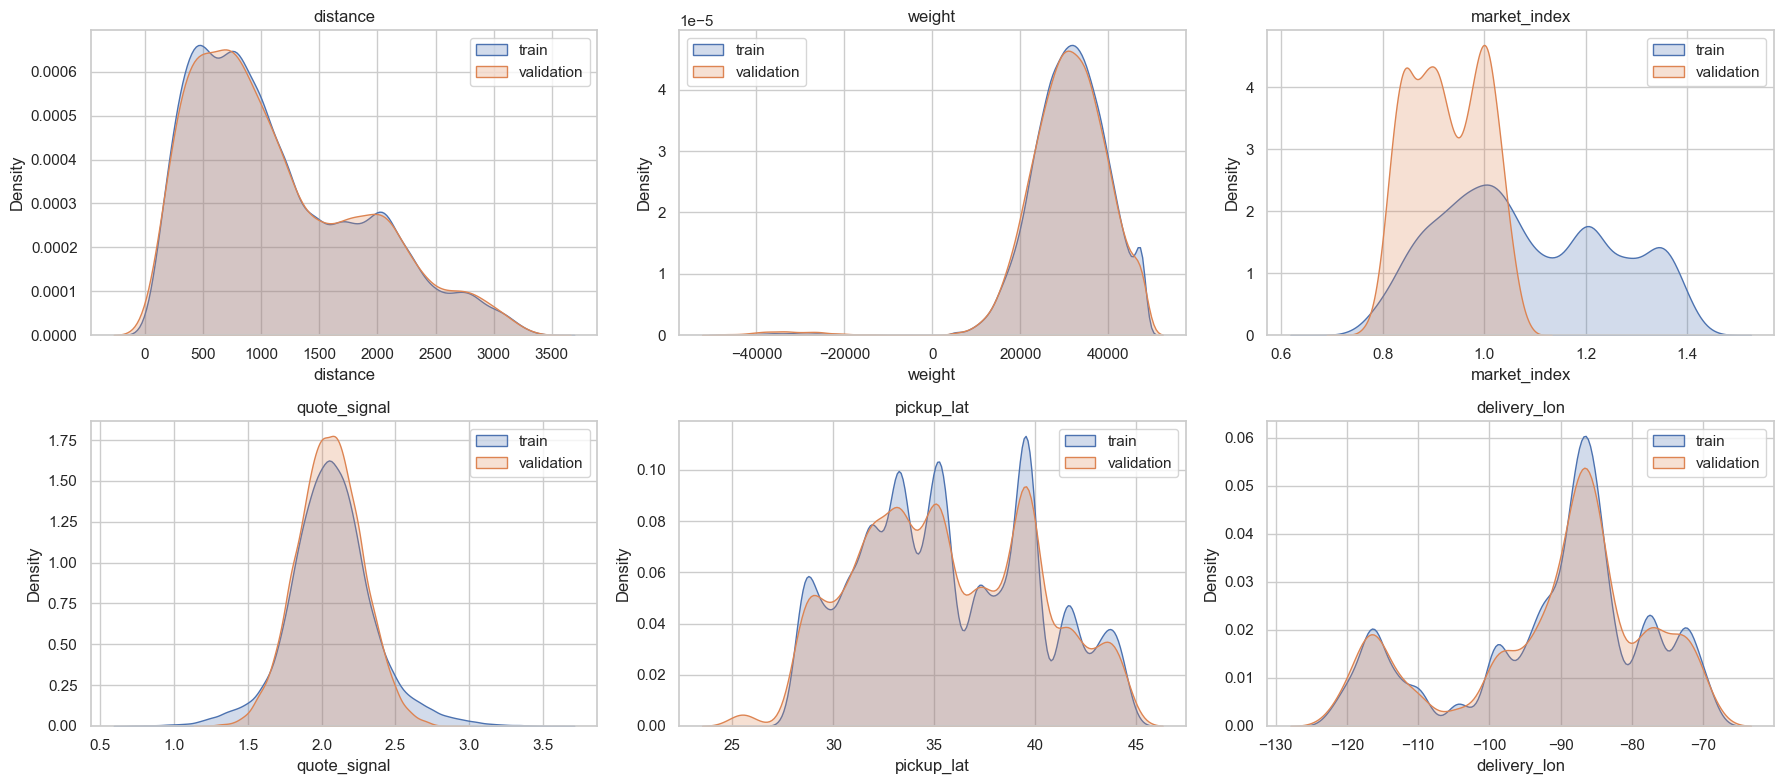

In [41]:
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, col in zip(axes.ravel(), ["distance", "weight", "market_index", "quote_signal", "pickup_lat", "delivery_lon"]):
    sns.kdeplot(train[col].dropna(), ax=ax, label="train", fill=True, common_norm=False)
    sns.kdeplot(valid[col].dropna(), ax=ax, label="validation", fill=True, common_norm=False)
    ax.set_title(col); ax.legend()
plt.tight_layout()
plt.show()

In [42]:
pd.concat({
    "train_%": 100 * train["equipment"].value_counts(normalize=True),
    "validation_%": 100 * valid["equipment"].value_counts(normalize=True),
}, axis=1)

,train_%,validation_%
equipment,,
Dry Van,56.6708,56.5000
Reefer,25.0937,25.4250
Flatbed,18.2354,18.0750


In [43]:
# Last month of train vs validation, for the time-dependent signals
last = t[t["date"] >= "2025-10-01"]
pd.DataFrame({
    "train_Oct": last[["market_index", "quote_signal", "distance", "weight"]].median(),
    "validation_Nov": valid[["market_index", "quote_signal", "distance", "weight"]].median(),
})

,train_Oct,validation_Nov
market_index,0.9582,0.9229
quote_signal,1.9858,2.0512
distance,937.3000,953.6000
weight,"31,447.0000","31,193.0000"


## 13. Findings

**Shape and coverage**
- Train: 48,000 loads, 2025-01-01 to 2025-10-31, every calendar day present (~160 loads/day).
- Validation: 12,000 loads, 2025-11-01 to 2025-12-31 (~195 loads/day). It is strictly *after* train, so validation must be time-based.
- Equipment mix is identical in train and validation (~57% Dry Van, 25% Reefer, 18% Flatbed). No label variants or whitespace issues in any categorical column.
- No duplicate `load_id`s, no duplicate rows, no ID overlap between train and validation.

**Data-quality issues**

| Issue | Train rows | Validation rows | Notes |
|---|---|---|---|
| Missing `weight` | 300 (0.6%) | 165 (1.4%) | Spread evenly across months and equipment |
| Missing `market_index` | 374 (0.8%) | 249 (2.1%) | Independent of missing weight (only 1 row has both) |
| Negative `weight` | 292 | 145 | Absolute values (5,000-47,500) look like valid weights, so likely a sign error |
| `weight` stuck at 47,500 | ~1,190 | ~300 | Pile-up at the maximum suggests values were capped |
| `distance` > 1.5x straight-line | 214 | 55 | Normal ratio is ~1.18; 22 train rows exceed 2x (max 9.6x) |
| Rate per mile > $5 | 317 | - | About 3.5x the typical rate for that distance and equipment |
| Rate per mile < $1 | 329 | - | About 0.28x typical; suspected corruption |

- Coordinates are internally consistent (one pair per city) but do not match real geography (e.g. Phoenix at latitude 28.8), so treat them as synthetic location codes rather than true positions.
- Most distance-flagged rows are **not** clearly wrong: their stated distance is only ~1.14x the same-lane median, and their rate fits the stated distance (~$2.91/mi, plausible for short trips) far better than the straight-line estimate (~$4.04/mi). The flag mostly marks short trips, where road distance naturally exceeds straight-line distance by more.
- `market_index` behaves like a daily value: within-day spread (~0.025) is small compared with the spread across days (~0.17).
- 8 validation cities never appear in train (Allentown, Charlotte, Chicago, Jackson, Knoxville, Laredo, Norfolk, San Diego), touching 1,447 validation rows. 736 validation lanes (1,461 rows) are unseen in train.

**Relationships**
- `distance` dominates: Spearman 0.98 with `posted_rate`. Rate per mile still falls steadily with distance (Dry Van ~$2.63 under 250 mi to ~$1.80 over 2,500 mi), so rate per mile does not fully normalise the target.
- Equipment premium is consistent across distance bands: Reefer ~13% and Flatbed ~8% above Dry Van.
- Weight has a small positive effect on rate per mile (Spearman 0.20).
- `market_index` barely correlates with raw rate (distance swamps it), but at the daily level it tracks median rate per mile closely (Spearman 0.64). It has a strong weekly cycle and a high regime from May to July.
- `quote_signal` is nearly uncorrelated with rate per mile (0.09 per row, -0.09 daily) and moves in abrupt step changes rather than trends. Its usefulness should be tested on time holdouts before relying on it.
- Median rate per mile rose from ~$2.03 (Jan) to ~$2.25 (Jun), then settled around $2.12-2.16 (Aug-Oct).

**December lane (Lexington to Fort Wayne)**
- 32 historical loads (21 Dry Van), all at ~350-385 miles. Dry Van rates are ~$780-$935 (~$2.20-$2.47 per mile), giving a sanity range for the December chart.
- The chart inputs lack coordinates, `market_index` and `quote_signal`, but none need to be assumed: `validation.csv` covers every December date, so daily values come from its same-date medians, and both cities are in the coordinate lookup.

**Cleaning decisions (fixed)**
1. Negative weights: take the absolute value.
2. Weights at 47,500: keep the value and add a `weight_is_capped` flag.
3. Missing weight: impute with the equipment median, fitted on training data only (within each fold).
4. Missing `market_index`: impute with the same-date median (validation rows use validation dates).
5. December features: same-date medians of `market_index` and `quote_signal` from `validation.csv`; coordinates from the city lookup.

**Validation design**
- Rolling monthly splits: Jan-Jun -> Jul, Jan-Jul -> Aug, Jan-Aug -> Sep, Jan-Sep -> Oct. Choose the model on average and October performance, then retrain on all data.
- Fit all imputers, encodings and frequency features inside each fold's training months only.
- Report MAE and RMSE in dollars, both on all holdout rows and with suspected corrupt rates excluded, since the corrupted rows also sit in every holdout month.

**Experiments (decided by rolling validation, not fixed in advance)**
- *Distance:* keep the original distance and add haversine distance, the distance/haversine ratio and an anomaly flag. Only replace distance if validation shows it helps; validation rows can never be dropped.
- *Rate outliers:* compare all rows with a robust loss (default), winsorised or down-weighted targets, and excluding suspected corruptions.
- *Target:* compare raw `posted_rate`, log(`posted_rate`), and rate per mile multiplied back by distance, all evaluated in dollars.
- *Lane information:* use lane and city categories (in-fold target encoding or native categorical handling) alongside coordinates, distance, equipment, weight, date, `market_index` and lane-frequency features, so unseen lanes fall back on general features.
- Start from one baseline (robust loss, log target, all rows, original distance plus flags) and change one thing at a time.
